# Retail Customer Segmentation & Profitability Analysis

**Business question:** How can observed customer purchasing behaviour and profitability inform retention and marketing priorities without relying on revenue alone?

**Data:** 2014–2017 Superstore transactional records (9,994 order lines; 793 customers) and two monthly U.S. Census retail sales benchmarks (48 observations each). The Census series provide market context, not a comparison of identical businesses.

**Approach:** Transaction validation → exploratory analysis → RFM and customer Profit → log/signed-log transformations → standardisation → K-means model selection → segment and discount analysis → unadjusted U.S. retail benchmarking.

Run from the repository root after placing `Superstore.csv` and `Census.xlsx` in `data/` as described in the [README](README.md). All customer value metrics represent *observed 2014–2017 history*, not forecast customer lifetime value.

## 1. Libraries and Superstore transactional data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('data/Superstore.csv', encoding='latin1')

## 2. Exploring the dataset

In [3]:
print(df.shape)

(9994, 21)


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [5]:
display(df.head())

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [6]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [7]:
print("Exact duplicate rows:", df.duplicated().sum())

Exact duplicate rows: 0


In [8]:
df.dtypes

Row ID             int64
Order ID          object
Order Date        object
Ship Date         object
Ship Mode         object
Customer ID       object
Customer Name     object
Segment           object
Country           object
City              object
State             object
Postal Code        int64
Region            object
Product ID        object
Category          object
Sub-Category      object
Product Name      object
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

In [9]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%m/%d/%Y",
    errors="coerce"
)

In [10]:
df[["Order Date", "Sales", "Profit", "Discount", "Quantity"]].isnull().sum()

Order Date    0
Sales         0
Profit        0
Discount      0
Quantity      0
dtype: int64

In [11]:
df[["Sales", "Profit", "Discount", "Quantity"]].describe()

,Sales,Profit,Discount,Quantity
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,28.656896,0.156203,3.789574
std,623.245101,234.260108,0.206452,2.225110
min,0.444000,-6599.978000,0.000000,1.000000
25%,17.280000,1.728750,0.000000,2.000000
50%,54.490000,8.666500,0.200000,3.000000
75%,209.940000,29.364000,0.200000,5.000000
max,22638.480000,8399.976000,0.800000,14.000000


In [12]:
print("Date range:")
print(df["Order Date"].min(), "to", df["Order Date"].max())

print("\nUnique customers:")
print(df["Customer ID"].nunique())

Date range:
2014-01-03 00:00:00 to 2017-12-30 00:00:00

Unique customers:
793


## 3. Univariate Exploratory Data Analysis


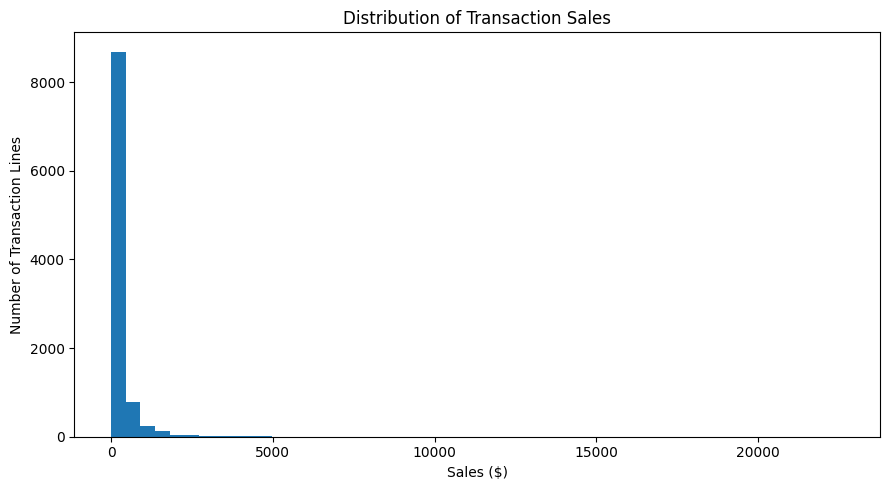

In [13]:
plt.figure(figsize=(9, 5))

plt.hist(df["Sales"].dropna(), bins=50)

plt.title("Distribution of Transaction Sales")
plt.xlabel("Sales ($)")
plt.ylabel("Number of Transaction Lines")

plt.tight_layout()
plt.show()

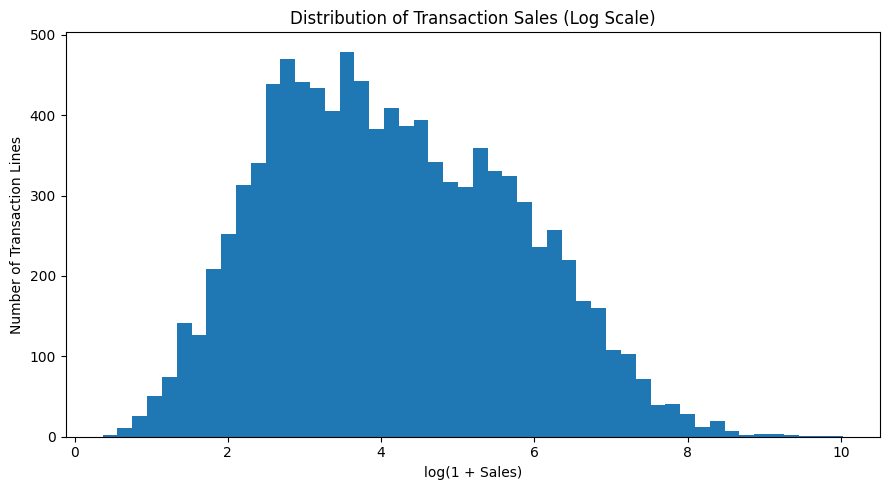

In [14]:
plt.figure(figsize=(9, 5))

plt.hist(np.log1p(df["Sales"].clip(lower=0)), bins=50)

plt.title("Distribution of Transaction Sales (Log Scale)")
plt.xlabel("log(1 + Sales)")
plt.ylabel("Number of Transaction Lines")

plt.tight_layout()
plt.show()

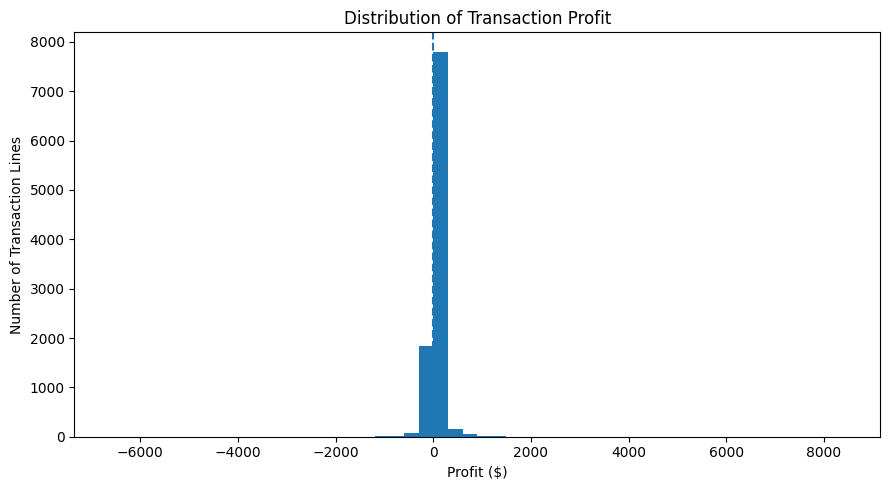

In [15]:
plt.figure(figsize=(9, 5))

plt.hist(df["Profit"].dropna(), bins=50)

plt.axvline(0, linestyle="--")

plt.title("Distribution of Transaction Profit")
plt.xlabel("Profit ($)")
plt.ylabel("Number of Transaction Lines")

plt.tight_layout()
plt.show()

In [16]:
print("Median profit:", df["Profit"].median())
print("Mean profit:", df["Profit"].mean())

print(
    "Percentage of loss-making transaction lines:",
    (df["Profit"] < 0).mean() * 100
)

Median profit: 8.6665
Mean profit: 28.65689630778467
Percentage of loss-making transaction lines: 18.721232739643785


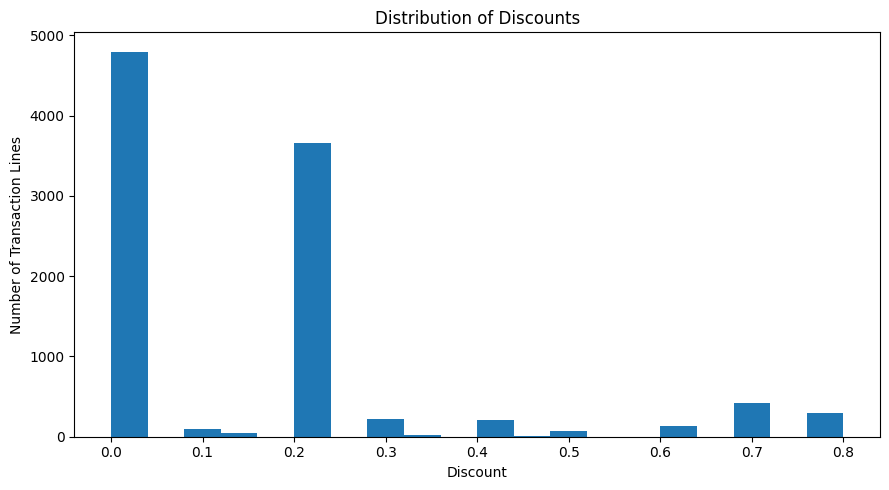

In [17]:
plt.figure(figsize=(9, 5))

plt.hist(df["Discount"].dropna(), bins=20)

plt.title("Distribution of Discounts")
plt.xlabel("Discount")
plt.ylabel("Number of Transaction Lines")

plt.tight_layout()
plt.show()

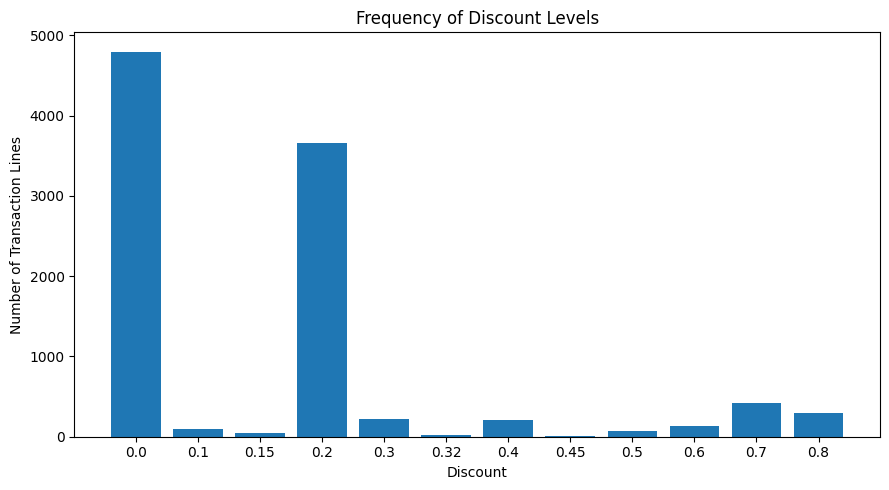

In [18]:
discount_counts = (
    df["Discount"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(9, 5))

plt.bar(
    discount_counts.index.astype(str),
    discount_counts.values
)

plt.title("Frequency of Discount Levels")
plt.xlabel("Discount")
plt.ylabel("Number of Transaction Lines")

plt.tight_layout()
plt.show()

In [19]:
discount_profit = (
    df.groupby("Discount", as_index=False)["Profit"]
      .mean()
)

display(discount_profit)

,Discount,Profit
0,0.00,66.900292
1,0.10,96.055074
2,0.15,27.288298
3,0.20,24.702572
4,0.30,-45.679636
5,0.32,-88.560656
6,0.40,-111.927429
7,0.45,-226.646464
8,0.50,-310.703456
9,0.60,-43.077212


In [20]:
customer_frequency = (
    df.groupby("Customer ID")["Order ID"]
      .nunique()
)

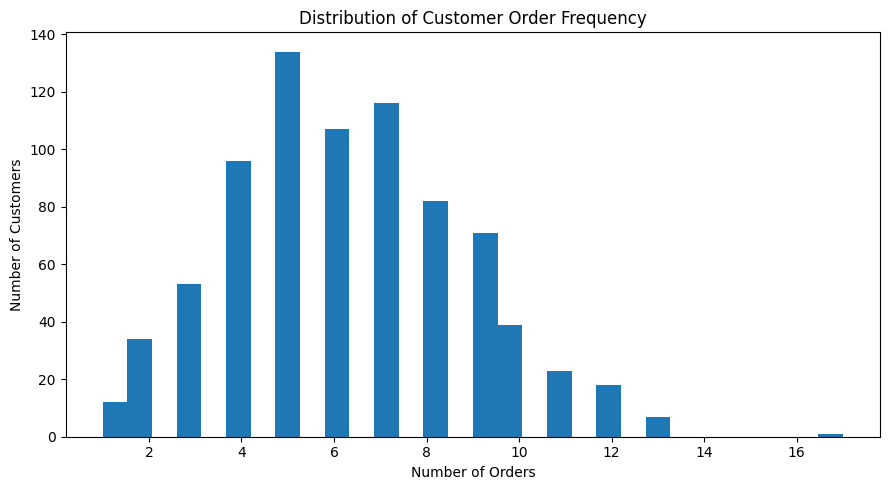

In [21]:
plt.figure(figsize=(9, 5))

plt.hist(customer_frequency, bins=30)

plt.title("Distribution of Customer Order Frequency")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

## 4. Customer-Level RFM Construction

Recency is measured against **31 December 2017**, one day after the most recent observed order. Frequency counts **unique Order IDs**, not transaction lines. Monetary and Profit values are historical sums for each customer.


In [22]:
reference_date = df["Order Date"].max() + pd.Timedelta(days=1)

print(reference_date)

2017-12-31 00:00:00


In [23]:
if "Order ID" in df.columns:

    customer_df = (
        df.groupby("Customer ID")
        .agg(
            last_purchase=("Order Date", "max"),
            frequency=("Order ID", "nunique"),
            monetary=("Sales", "sum"),
            profit=("Profit", "sum"),
            quantity=("Quantity", "sum")
        )
        .reset_index()
    )

else:

    customer_df = (
        df.groupby("Customer ID")
        .agg(
            last_purchase=("Order Date", "max"),
            frequency=("Order Date", "nunique"),
            monetary=("Sales", "sum"),
            profit=("Profit", "sum"),
            quantity=("Quantity", "sum")
        )
        .reset_index()
    )

In [24]:
customer_df["recency"] = (
    reference_date - customer_df["last_purchase"]
).dt.days

In [25]:
customer_df["profit_margin"] = np.where(
    customer_df["monetary"] != 0,
    customer_df["profit"] / customer_df["monetary"],
    np.nan
)

In [26]:
display(customer_df.head())

customer_df[
    ["recency", "frequency", "monetary", "profit", "profit_margin"]
].describe().T

,Customer ID,last_purchase,frequency,monetary,profit,quantity,recency,profit_margin
0,AA-10315,2017-06-29,5,5563.560,-362.8825,30,185,-0.065225
1,AA-10375,2017-12-11,9,1056.390,277.3824,41,20,0.262576
2,AA-10480,2017-04-15,4,1790.512,435.8274,36,260,0.243409
3,AA-10645,2017-11-05,6,5086.935,857.8033,64,56,0.168629
4,AB-10015,2016-11-10,3,886.156,129.3465,13,416,0.145964


,count,mean,std,min,25%,50%,75%,max
recency,793.0,147.802018,186.211051,1.000000,31.000000,76.000000,184.000000,1166.000000
frequency,793.0,6.316520,2.550885,1.000000,5.000000,6.000000,8.000000,17.000000
monetary,793.0,2896.848500,2628.670117,4.833000,1146.050000,2256.394000,3785.276000,25043.050000
profit,793.0,361.156396,894.261812,-6626.389500,36.613100,227.833800,560.007800,8981.323900
profit_margin,793.0,0.110242,0.191819,-1.164556,0.041806,0.144153,0.223319,0.475305


In [27]:
customer_df["R_score"] = pd.qcut(
    customer_df["recency"],
    q=4,
    labels=[4, 3, 2, 1],
    duplicates="drop"
)

customer_df["F_score"] = pd.qcut(
    customer_df["frequency"].rank(method="first"),
    q=4,
    labels=[1, 2, 3, 4]
)

customer_df["M_score"] = pd.qcut(
    customer_df["monetary"].rank(method="first"),
    q=4,
    labels=[1, 2, 3, 4]
)

In [28]:
customer_df["R_score"] = customer_df["R_score"].astype(int)
customer_df["F_score"] = customer_df["F_score"].astype(int)
customer_df["M_score"] = customer_df["M_score"].astype(int)

In [29]:
customer_df["RFM_score"] = (
    customer_df["R_score"] +
    customer_df["F_score"] +
    customer_df["M_score"]
)

In [30]:
customer_df.sort_values(
    "RFM_score",
    ascending=False
).head(20)

,Customer ID,last_purchase,frequency,monetary,profit,quantity,recency,profit_margin,R_score,F_score,M_score,RFM_score
790,YS-21880,2017-12-21,8,6720.4440,1778.2923,58,10,0.264609,4,4,4,12
756,TP-21130,2017-12-22,9,4454.0560,1129.1261,55,9,0.253505,4,4,4,12
31,AH-10210,2017-12-24,9,4805.3440,1308.5546,53,7,0.272312,4,4,4,12
35,AI-10855,2017-12-17,10,4375.7860,867.7271,72,14,0.198302,4,4,4,12
82,BF-11170,2017-12-14,11,5907.9720,1538.2127,102,17,0.260362,4,4,4,12
438,KM-16720,2017-12-02,8,4909.4720,745.7685,98,29,0.151904,4,4,4,12
433,KL-16555,2017-12-14,8,5016.4880,-182.7813,84,17,-0.036436,4,4,4,12
387,JL-15835,2017-12-09,11,9799.9230,228.9070,143,22,0.023358,4,4,4,12
278,ES-14080,2017-12-02,9,4657.9240,246.6661,77,29,0.052956,4,4,4,12
275,EP-13915,2017-12-18,17,5478.0608,144.9578,124,13,0.026462,4,4,4,12


In [31]:
customer_df["P_score"] = pd.qcut(
    customer_df["profit"].rank(method="first"),
    q=4,
    labels=[1, 2, 3, 4]
).astype(int)

In [32]:
customer_df[
    [
        "Customer ID",
        "recency",
        "frequency",
        "monetary",
        "profit",
        "profit_margin",
        "RFM_score",
        "P_score"
    ]
].head()

,Customer ID,recency,frequency,monetary,profit,profit_margin,RFM_score,P_score
0,AA-10315,185,5,5563.560,-362.8825,-0.065225,6,1
1,AA-10375,20,9,1056.390,277.3824,0.262576,9,3
2,AA-10480,260,4,1790.512,435.8274,0.243409,4,3
3,AA-10645,56,6,5086.935,857.8033,0.168629,9,4
4,AB-10015,416,3,886.156,129.3465,0.145964,3,2


## 5. Feature Preparation for Clustering


RFM quartile scores above provide an interpretable, rule-based view of customer value.  
K-means is used below as the principal data-driven segmentation approach, with Profit retained alongside RFM variables because high revenue does not necessarily imply high profitability.


In [33]:
cluster_features = [
    "recency",
    "frequency",
    "monetary",
    "profit"
]

customer_df[cluster_features].describe().T

,count,mean,std,min,25%,50%,75%,max
recency,793.0,147.802018,186.211051,1.0000,31.0000,76.0000,184.0000,1166.0000
frequency,793.0,6.316520,2.550885,1.0000,5.0000,6.0000,8.0000,17.0000
monetary,793.0,2896.848500,2628.670117,4.8330,1146.0500,2256.3940,3785.2760,25043.0500
profit,793.0,361.156396,894.261812,-6626.3895,36.6131,227.8338,560.0078,8981.3239


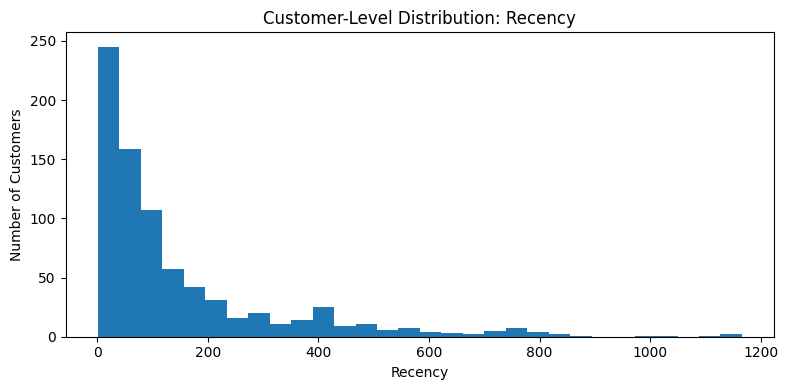

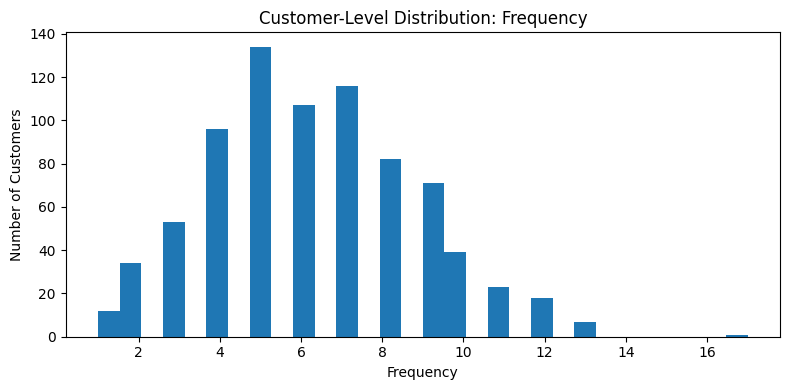

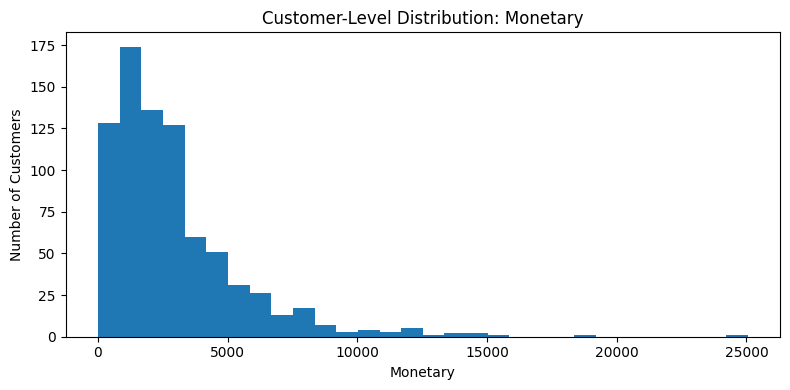

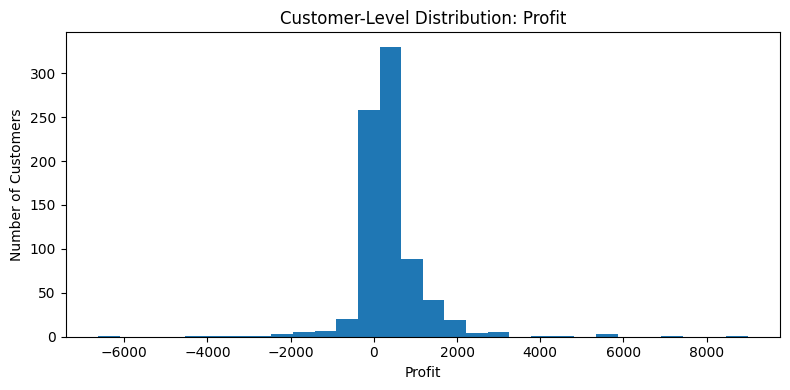

In [34]:
for variable in cluster_features:

    plt.figure(figsize=(8, 4))

    plt.hist(
        customer_df[variable].dropna(),
        bins=30
    )

    plt.title(f"Customer-Level Distribution: {variable.title()}")
    plt.xlabel(variable.title())
    plt.ylabel("Number of Customers")

    plt.tight_layout()
    plt.show()

In [35]:
cluster_data = customer_df[
    ["recency", "frequency", "monetary", "profit"]
].copy()

cluster_data["recency"] = np.log1p(cluster_data["recency"])
cluster_data["frequency"] = np.log1p(cluster_data["frequency"])
cluster_data["monetary"] = np.log1p(cluster_data["monetary"])

cluster_data["profit"] = (
    np.sign(cluster_data["profit"]) *
    np.log1p(np.abs(cluster_data["profit"]))
)

In [36]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(cluster_data)

## 6. K-Means Customer Segmentation


In [37]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 9)

inertias = []
silhouette_scores = []

for k in k_values:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

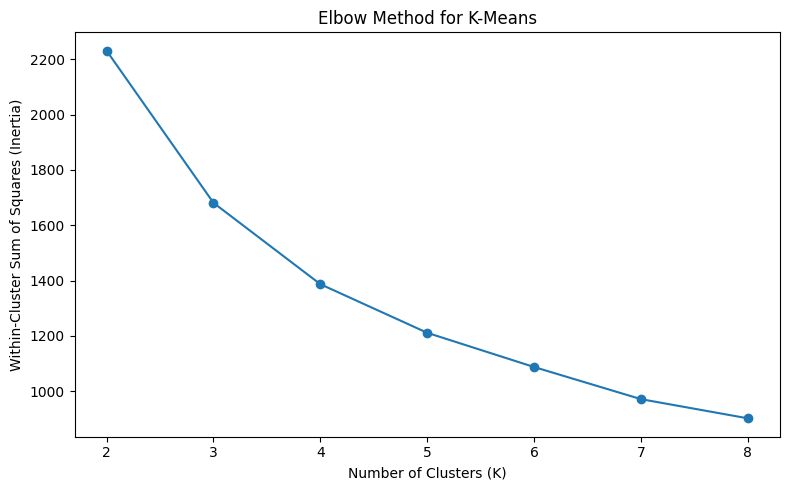

In [38]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertias,
    marker="o"
)

plt.title("Elbow Method for K-Means")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Within-Cluster Sum of Squares (Inertia)")

plt.xticks(list(k_values))

plt.tight_layout()
plt.show()

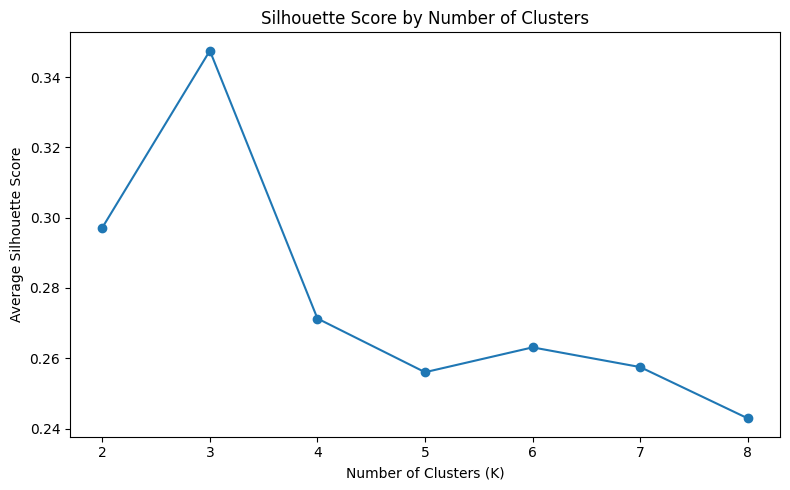

In [39]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)

plt.title("Silhouette Score by Number of Clusters")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Average Silhouette Score")

plt.xticks(list(k_values))

plt.tight_layout()
plt.show()

In [40]:
evaluation = pd.DataFrame({
    "K": list(k_values),
    "Inertia": inertias,
    "Silhouette": silhouette_scores
})

display(evaluation)

,K,Inertia,Silhouette
0,2,2230.590750,0.297156
1,3,1680.873916,0.347488
2,4,1386.870671,0.271310
3,5,1211.237040,0.256033
4,6,1087.585430,0.263100
5,7,971.479870,0.257498
6,8,902.196433,0.242912


In [41]:
from sklearn.cluster import KMeans

# Testing K=3 because it produced the highest silhouette score
kmeans_3 = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=20
)

customer_df["cluster_k3"] = kmeans_3.fit_predict(X_scaled)

profile_k3 = (
    customer_df
    .groupby("cluster_k3")
    .agg(
        customers=("Customer ID", "nunique"),
        avg_recency=("recency", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_sales=("monetary", "mean"),
        avg_profit=("profit", "mean"),
        avg_profit_margin=("profit_margin", "mean"),
        total_sales=("monetary", "sum"),
        total_profit=("profit", "sum")
    )
    .round(2)
)

display(profile_k3)

,customers,avg_recency,avg_frequency,avg_sales,avg_profit,avg_profit_margin,total_sales,total_profit
cluster_k3,,,,,,,,
0,446,88.89,7.55,3838.41,721.85,0.18,1711929.29,321946.23
1,137,154.04,6.11,2808.32,-512.92,-0.18,384740.17,-70270.16
2,210,268.85,3.83,954.91,165.34,0.16,200531.40,34720.95


In [42]:
# Creating a separate K=4 solution so it can be compared directly with K=3
kmeans_4 = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=20
)

customer_df["cluster_k4"] = kmeans_4.fit_predict(X_scaled)

comparison = pd.crosstab(
    customer_df["cluster_k4"],
    customer_df["cluster_k3"],
    margins=True
)

display(comparison)


cluster_k3,0,1,2,All
cluster_k4,,,,
0,191,0,87,278
1,255,0,2,257
2,0,11,121,132
3,0,126,0,126
All,446,137,210,793


### Final choice of K: K=4

K=3 achieved the highest silhouette score (0.347), indicating stronger statistical cluster separation than K=4 (0.271). However, cross-tabulation of the two solutions showed that K=3 largely combines the highly recent and active **High-Value Loyal** customers with the less-recent but still profitable **Established Profitable** customers. These groups have different managerial implications, particularly **retention** for highly active customers versus **re-engagement** for valuable customers whose purchasing activity is less recent. Therefore, **K=4 is retained as the final segmentation solution**, accepting a modest reduction in statistical compactness in exchange for greater managerial interpretability and marketing actionability.


In [43]:
# Final segmentation: retained K=4 based on managerial interpretability and actionability
optimal_k = 4

kmeans = KMeans(
    n_clusters=optimal_k,
    random_state=42,
    n_init=20
)

customer_df["cluster"] = kmeans.fit_predict(X_scaled)

In [44]:
customer_df["cluster"].value_counts().sort_index()

cluster
0    278
1    257
2    132
3    126
Name: count, dtype: int64

## 7. Cluster Profiling and Visualisation


In [45]:
cluster_profile = (
    customer_df
    .groupby("cluster")
    .agg(
        customers=("Customer ID", "nunique"),
        avg_recency=("recency", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_sales=("monetary", "mean"),
        total_sales=("monetary", "sum"),
        avg_profit=("profit", "mean"),
        total_profit=("profit", "sum"),
        avg_profit_margin=("profit_margin", "mean")
    )
    .round(2)
)

display(cluster_profile)

,customers,avg_recency,avg_frequency,avg_sales,total_sales,avg_profit,total_profit,avg_profit_margin
cluster,,,,,,,,
0,278,199.76,6.27,3016.81,838674.27,607.24,168813.92,0.18
1,257,31.00,8.00,3915.75,1006348.24,692.94,178086.08,0.17
2,132,279.07,3.06,582.44,76881.83,52.84,6975.19,0.11
3,126,133.89,6.38,2978.54,375296.52,-535.54,-67478.17,-0.17


In [46]:
cluster_profile["customer_pct"] = (
    cluster_profile["customers"] /
    cluster_profile["customers"].sum()
    * 100
).round(1)

display(cluster_profile)

,customers,avg_recency,avg_frequency,avg_sales,total_sales,avg_profit,total_profit,avg_profit_margin,customer_pct
cluster,,,,,,,,,
0,278,199.76,6.27,3016.81,838674.27,607.24,168813.92,0.18,35.1
1,257,31.00,8.00,3915.75,1006348.24,692.94,178086.08,0.17,32.4
2,132,279.07,3.06,582.44,76881.83,52.84,6975.19,0.11,16.6
3,126,133.89,6.38,2978.54,375296.52,-535.54,-67478.17,-0.17,15.9


In [47]:
cluster_names = {
    0: "Established Profitable",
    1: "High-Value Loyal",
    2: "Low-Value Dormant",
    3: "High-Revenue Loss-Making"
}

customer_df["segment"] = customer_df["cluster"].map(cluster_names)


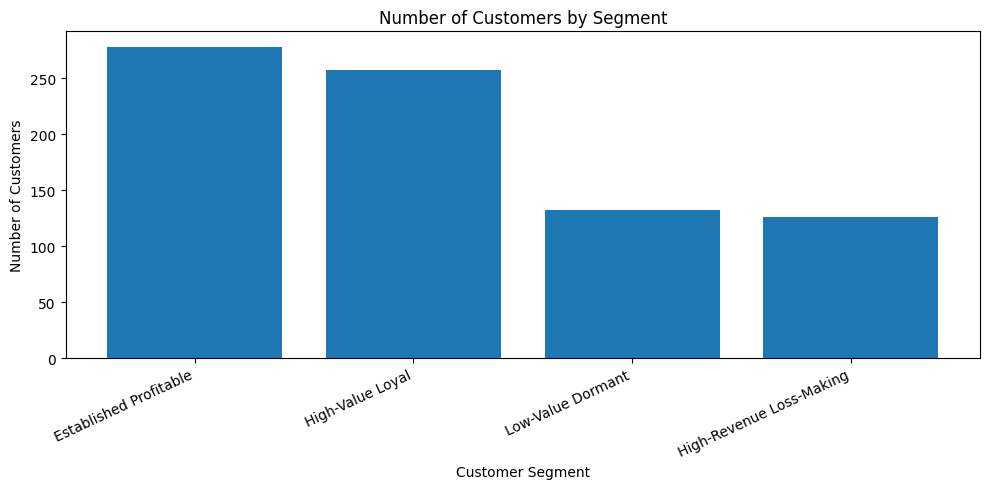

In [48]:
segment_counts = (
    customer_df["segment"]
    .value_counts()
)

plt.figure(figsize=(10, 5))

plt.bar(
    segment_counts.index,
    segment_counts.values
)

plt.title("Number of Customers by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

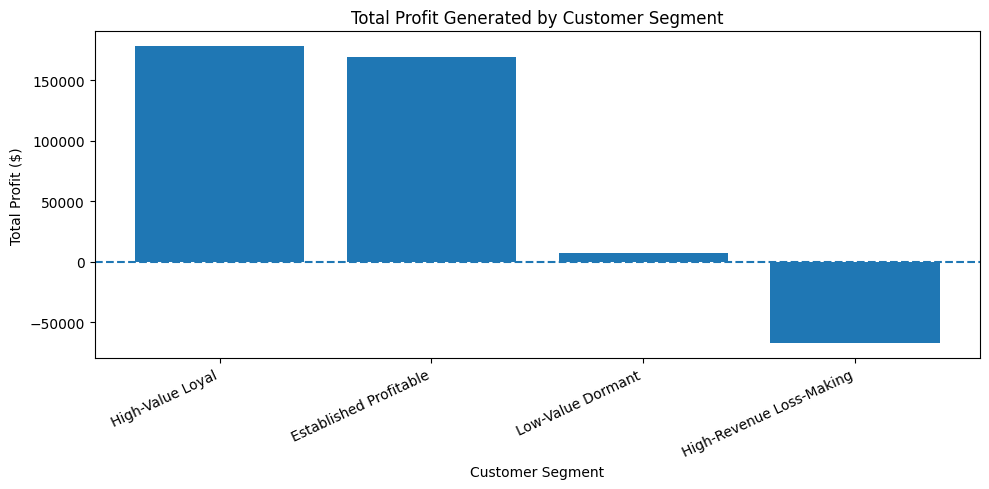

In [49]:
segment_profit = (
    customer_df
    .groupby("segment")["profit"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

plt.bar(
    segment_profit.index,
    segment_profit.values
)

plt.axhline(0, linestyle="--")

plt.title("Total Profit Generated by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Total Profit ($)")

plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

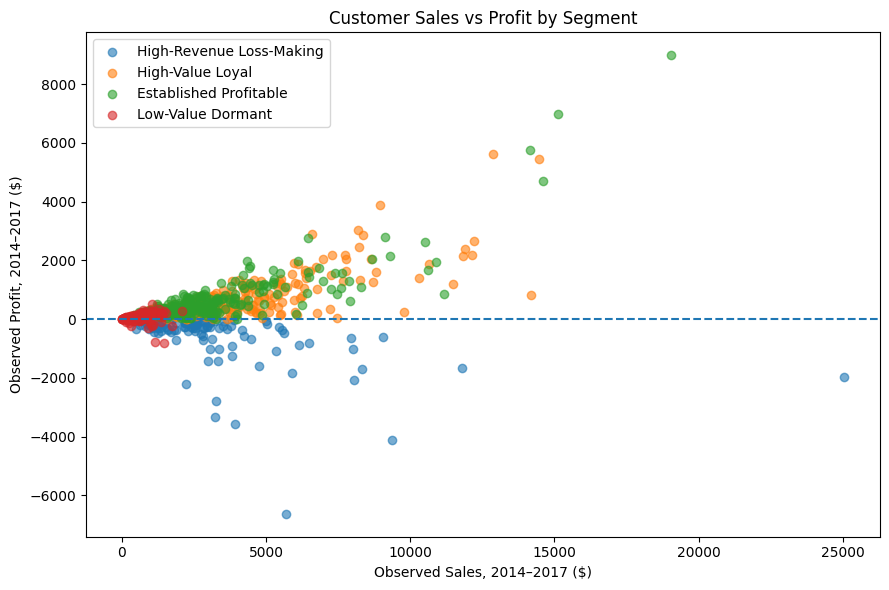

In [50]:
plt.figure(figsize=(9, 6))

for segment in customer_df["segment"].unique():

    subset = customer_df[
        customer_df["segment"] == segment
    ]

    plt.scatter(
        subset["monetary"],
        subset["profit"],
        alpha=0.6,
        label=segment
    )

plt.axhline(0, linestyle="--")

plt.title("Customer Sales vs Profit by Segment")
plt.xlabel("Observed Sales, 2014–2017 ($)")
plt.ylabel("Observed Profit, 2014–2017 ($)")
plt.legend()

plt.tight_layout()
plt.show()

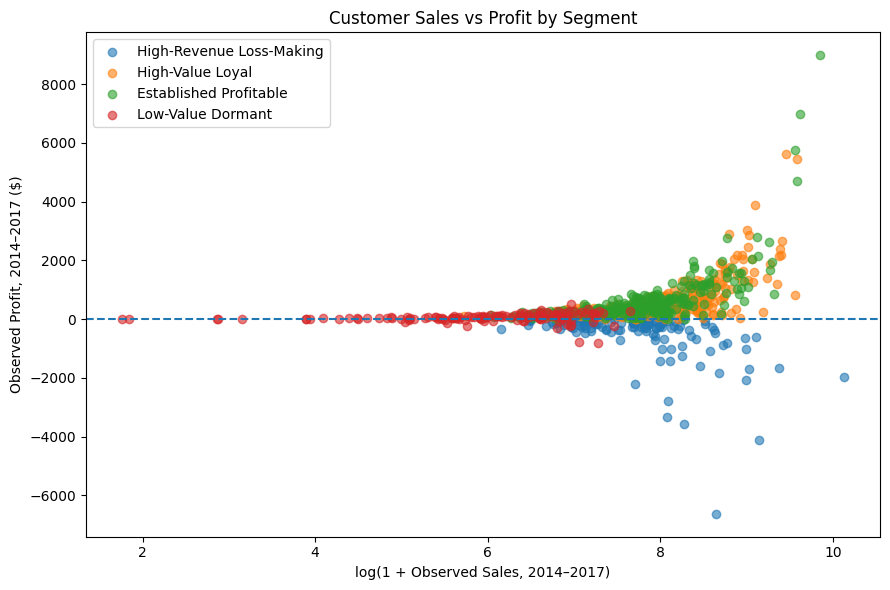

In [51]:
plt.figure(figsize=(9, 6))

for segment in customer_df["segment"].unique():

    subset = customer_df[
        customer_df["segment"] == segment
    ]

    plt.scatter(
        np.log1p(subset["monetary"]),
        subset["profit"],
        alpha=0.6,
        label=segment
    )

plt.axhline(0, linestyle="--")

plt.title("Customer Sales vs Profit by Segment")
plt.xlabel("log(1 + Observed Sales, 2014–2017)")
plt.ylabel("Observed Profit, 2014–2017 ($)")
plt.legend()

plt.tight_layout()
plt.show()

In [52]:
profile_for_plot = (
    customer_df
    .groupby("segment")[
        ["recency", "frequency", "monetary", "profit"]
    ]
    .mean()
)

profile_z = (
    profile_for_plot - profile_for_plot.mean()
) / profile_for_plot.std()

# Applying reverse recency so higher values consistently indicate stronger/more recent activity
profile_z["recency"] = -profile_z["recency"]

profile_z = profile_z.rename(
    columns={
        "recency": "Recent Activity",
        "frequency": "Frequency",
        "monetary": "Monetary Value",
        "profit": "Profit"
    }
)

display(profile_z)


,Recent Activity,Frequency,Monetary Value,Profit
segment,,,,
Established Profitable,-0.369824,0.166019,0.275531,0.707979
High-Revenue Loss-Making,0.257510,0.217984,0.248729,-1.300270
High-Value Loyal,1.237388,1.001981,0.905088,0.858578
Low-Value Dormant,-1.125074,-1.385985,-1.429347,-0.266287


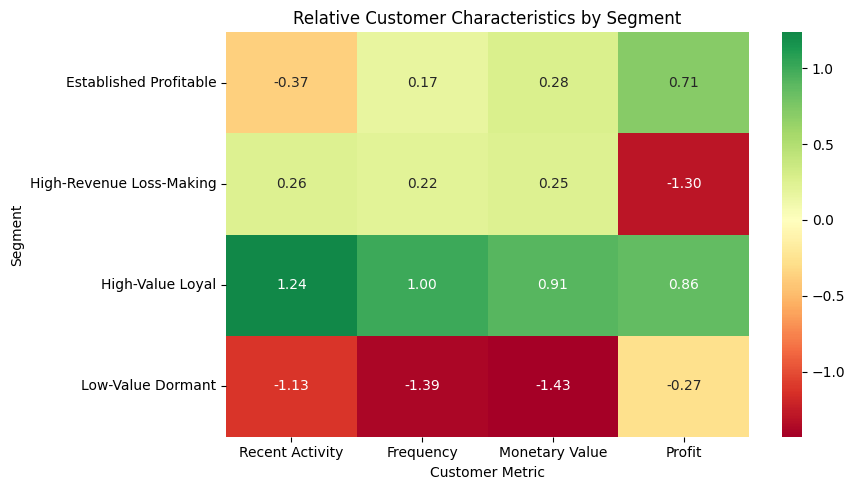

In [53]:
import seaborn as sns

plt.figure(figsize=(9, 5))

sns.heatmap(
    profile_z,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=0
)

plt.title("Relative Customer Characteristics by Segment")
plt.xlabel("Customer Metric")
plt.ylabel("Segment")

plt.tight_layout()
plt.show()

In [54]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

customer_df["PC1"] = X_pca[:, 0]
customer_df["PC2"] = X_pca[:, 1]

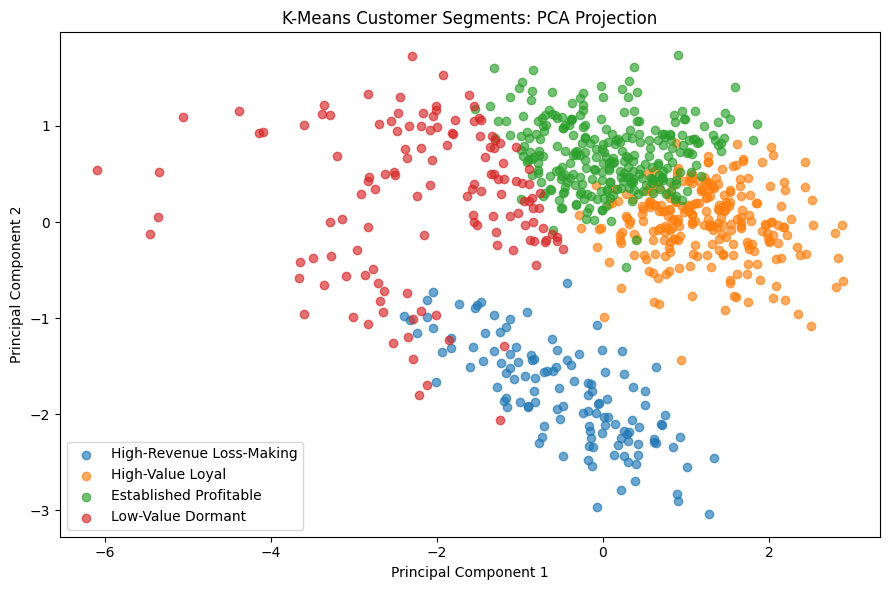

In [55]:
plt.figure(figsize=(9, 6))

for segment in customer_df["segment"].unique():

    subset = customer_df[
        customer_df["segment"] == segment
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        alpha=0.65,
        label=segment
    )

plt.title("K-Means Customer Segments: PCA Projection")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()

plt.tight_layout()
plt.show()

In [56]:
print(
    "Variance explained by PC1 and PC2:",
    pca.explained_variance_ratio_.sum()
)

Variance explained by PC1 and PC2: 0.7022110934354826


In [57]:
segment_means = (
    customer_df
    .groupby("segment")[
        ["recency", "frequency", "monetary", "profit"]
    ]
    .mean()
)

segment_means

,recency,frequency,monetary,profit
segment,,,,
Established Profitable,199.762590,6.273381,3016.813922,607.244301
High-Revenue Loss-Making,133.888889,6.380952,2978.543801,-535.541025
High-Value Loyal,30.996109,8.003891,3915.751921,692.941950
Low-Value Dormant,279.068182,3.060606,582.438086,52.842380


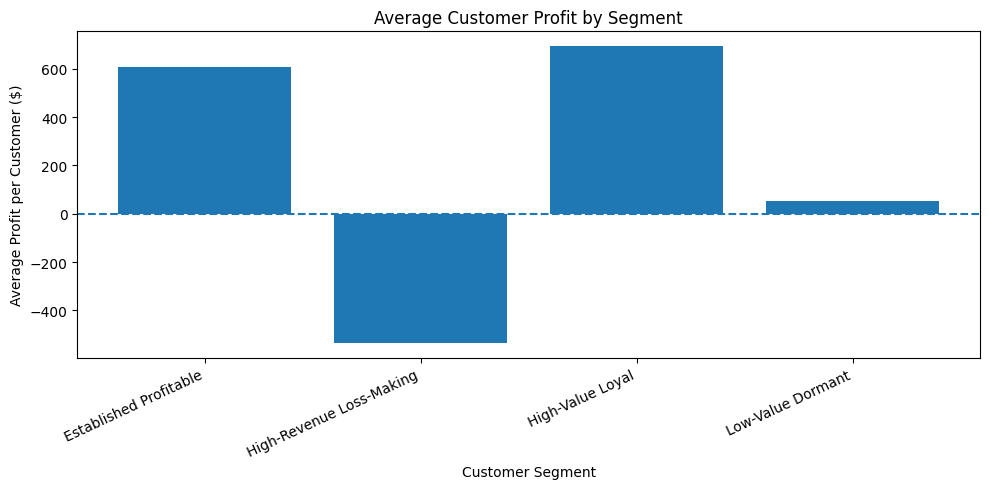

In [58]:
plt.figure(figsize=(10, 5))

plt.bar(
    segment_means.index,
    segment_means["profit"]
)

plt.axhline(0, linestyle="--")

plt.title("Average Customer Profit by Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Average Profit per Customer ($)")

plt.xticks(rotation=25, ha="right")

plt.tight_layout()
plt.show()

## 8. Business Interpretation and Segment Profiling


In [59]:
df_segmented = df.merge(
    customer_df[["Customer ID", "segment"]],
    on="Customer ID",
    how="left"
)

In [60]:
region_profile = pd.crosstab(
    df_segmented["segment"],
    df_segmented["Region"],
    normalize="index"
) * 100

display(region_profile.round(1))

Region,Central,East,South,West
segment,,,,
Established Profitable,22.4,27.1,15.6,34.9
High-Revenue Loss-Making,25.1,29.8,17.5,27.6
High-Value Loyal,23.2,28.7,16.2,31.9
Low-Value Dormant,23.4,30.9,16.1,29.6


In [61]:
category_profile = pd.crosstab(
    df_segmented["segment"],
    df_segmented["Category"],
    normalize="index"
) * 100

display(category_profile.round(1))

Category,Furniture,Office Supplies,Technology
segment,,,
Established Profitable,21.3,60.4,18.3
High-Revenue Loss-Making,23.5,59.8,16.6
High-Value Loyal,20.6,59.4,20.0
Low-Value Dormant,19.1,66.1,14.9


### Discount and loss-driver diagnostics

Reported mean discounts are **arithmetic averages across transaction lines**, not sales-weighted rates. The analysis below is observational and does not estimate the causal effect of changing discounts.


In [62]:
segment_discount_profile = (
    df_segmented
    .groupby("segment")
    .agg(
        avg_discount=("Discount", "mean"),
        median_discount=("Discount", "median"),
        total_sales=("Sales", "sum"),
        total_profit=("Profit", "sum")
    )
    .round(3)
    .sort_values("total_profit", ascending=False)
)

display(segment_discount_profile)


,avg_discount,median_discount,total_sales,total_profit
segment,,,,
High-Value Loyal,0.147,0.0,1006348.244,178086.081
Established Profitable,0.135,0.0,838674.270,168813.916
Low-Value Dormant,0.162,0.2,76881.827,6975.194
High-Revenue Loss-Making,0.223,0.2,375296.519,-67478.169


In [63]:
loss_segment = df_segmented[
    df_segmented["segment"] == "High-Revenue Loss-Making"
]

loss_subcategory = (
    loss_segment
    .groupby("Sub-Category")
    .agg(
        sales=("Sales", "sum"),
        profit=("Profit", "sum"),
        avg_discount=("Discount", "mean")
    )
    .sort_values("profit")
    .round(2)
)

display(loss_subcategory)


,sales,profit,avg_discount
Sub-Category,,,
Machines,63662.58,-25806.46,0.52
Binders,32455.41,-23672.14,0.49
Tables,54793.58,-17408.47,0.35
Bookcases,23928.38,-4823.42,0.30
Appliances,10432.37,-3226.78,0.30
Supplies,14169.18,-2215.53,0.10
Chairs,50934.94,-1052.26,0.20
Furnishings,13775.72,-927.11,0.22
Fasteners,550.69,155.59,0.13


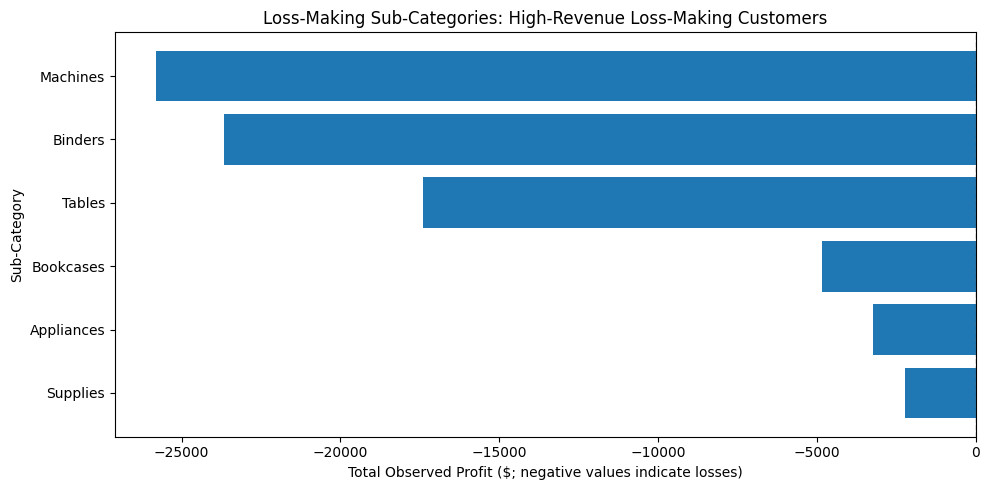

In [64]:
# Charting the six largest negative-profit sub-categories for this segment.
# Values are directly taken from loss_subcategory (no new estimation).
largest_losses = (
    loss_subcategory[loss_subcategory["profit"] < 0]
    .head(6)
    .sort_values("profit", ascending=False)
)
plt.figure(figsize=(10, 5))
plt.barh(largest_losses.index, largest_losses["profit"])
plt.axvline(0, linestyle="--", linewidth=1, color="gray")
plt.title("Loss-Making Sub-Categories: High-Revenue Loss-Making Customers")
plt.xlabel("Total Observed Profit ($; negative values indicate losses)")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()

## 9. External market context: U.S. Census retail data

This section reads the **NOT ADJUSTED** Monthly Retail Trade Survey data for 2014–2017. National retail totals and the furniture/home furnishings/electronics/appliance category offer context, but are not directly comparable in market coverage, scale or customer granularity with Superstore.

In [65]:
census_file = "data/Census.xlsx"

years = ["2014", "2015", "2016", "2017"]

census_raw = pd.read_excel(
    census_file,
    sheet_name=years,
    header=None
)

In [66]:
def extract_census_series(raw_sheet, year, target_label):

    # Column B contains the business/category descriptions
    labels = raw_sheet.iloc[:, 1].astype(str).str.strip()

    # For locating the start of the NOT ADJUSTED section
    not_adjusted_idx = labels[
        labels.str.contains(
            "NOT ADJUSTED",
            case=False,
            na=False
        )
    ].index[0]

    # To locate the later seasonally adjusted section
    adjusted_idx = labels[
        labels.str.match(
            r"ADJUSTED",
            case=False,
            na=False
        )
    ].index[0]

    # Restricting the search to NOT ADJUSTED data only
    section = raw_sheet.loc[
        not_adjusted_idx + 1 : adjusted_idx - 1
    ]

    section_labels = (
        section.iloc[:, 1]
        .astype(str)
        .str.strip()
    )

    # Locating the requested Kind of Business
    matches = section[
        section_labels.eq(target_label)
    ]

    if matches.empty:
        raise ValueError(
            f"Could not find '{target_label}' in {year}"
        )

    target_row = matches.iloc[0]

    # In this workbook, columns C:N contain Jan-Dec
    monthly_values = pd.to_numeric(
        target_row.iloc[2:14],
        errors="coerce"
    ).to_numpy()

    dates = pd.date_range(
        start=f"{year}-01-01",
        periods=12,
        freq="MS"
    )

    return pd.DataFrame({
        "Date": dates,
        "Sales": monthly_values
    })

In [67]:
total_frames = []

for year in years:

    yearly = extract_census_series(
        census_raw[year],
        year,
        "Retail and food services sales, total"
    )

    total_frames.append(yearly)

census_total = pd.concat(
    total_frames,
    ignore_index=True
)

census_total = census_total.rename(
    columns={"Sales": "Census Total Sales"}
)

display(census_total.head(15))

,Date,Census Total Sales
0,2014-01-01,376896
1,2014-02-01,373381
2,2014-03-01,425114
3,2014-04-01,423637
4,2014-05-01,450823
5,2014-06-01,425386
6,2014-07-01,435465
7,2014-08-01,443328
8,2014-09-01,413706
9,2014-10-01,430355


In [68]:
print(census_total.shape)
print(census_total["Date"].min())
print(census_total["Date"].max())

(48, 2)
2014-01-01 00:00:00
2017-12-01 00:00:00


In [69]:
furniture_frames = []

for year in years:

    yearly = extract_census_series(
        census_raw[year],
        year,
        "Furniture, home furn, electronics, and appliance stores"
    )

    furniture_frames.append(yearly)

census_furniture = pd.concat(
    furniture_frames,
    ignore_index=True
)

census_furniture = census_furniture.rename(
    columns={
        "Sales": "Census Furniture/Electronics Sales"
    }
)

display(census_furniture.head(15))

,Date,Census Furniture/Electronics Sales
0,2014-01-01,14847
1,2014-02-01,14857
2,2014-03-01,16023
3,2014-04-01,14762
4,2014-05-01,15810
5,2014-06-01,15238
6,2014-07-01,16039
7,2014-08-01,16656
8,2014-09-01,16302
9,2014-10-01,16252


In [70]:
print(census_furniture.shape)

(48, 2)


In [71]:
print("Census Total:")
display(census_total.head())

print("\nFurniture/Electronics:")
display(census_furniture.head())

Census Total:


,Date,Census Total Sales
0,2014-01-01,376896
1,2014-02-01,373381
2,2014-03-01,425114
3,2014-04-01,423637
4,2014-05-01,450823



Furniture/Electronics:


,Date,Census Furniture/Electronics Sales
0,2014-01-01,14847
1,2014-02-01,14857
2,2014-03-01,16023
3,2014-04-01,14762
4,2014-05-01,15810


In [72]:
# Check completeness of the extracted Census series
print("Missing values in Census total series:")
display(census_total.isnull().sum())

print("\nMissing values in Census furniture/electronics series:")
display(census_furniture.isnull().sum())

print("\nNumber of monthly observations:")
print("Census total:", len(census_total))
print("Census furniture/electronics:", len(census_furniture))


Missing values in Census total series:


Date                  0
Census Total Sales    0
dtype: int64


Missing values in Census furniture/electronics series:


Date                                  0
Census Furniture/Electronics Sales    0
dtype: int64


Number of monthly observations:
Census total: 48
Census furniture/electronics: 48


### Additional exploratory analysis of the Census dataset

Before comparing the Census series with Superstore, the two Census benchmarks are examined independently. This adds a **univariate review of central tendency and dispersion** and a **time-series review of month-to-month variability**. The coefficient of variation (CV) is included because the two Census series are on very different absolute scales, while percentage changes allow their short-run volatility to be compared more meaningfully.

Because the analysis uses **NOT ADJUSTED** Census data, these monthly changes retain normal seasonal effects. They are therefore interpreted descriptively rather than as evidence of structural market shocks.

In [73]:
# Independent descriptive exploration of the two Census series
census_exploration = (
    census_total
    .merge(
        census_furniture,
        on="Date",
        how="inner"
    )
    .copy()
)

census_series = [
    "Census Total Sales",
    "Census Furniture/Electronics Sales"
]

# Month-to-month percentage changes
for column in census_series:
    census_exploration[f"{column} MoM %"] = (
        census_exploration[column]
        .pct_change() * 100
    )

# Descriptive statistics and scale-adjusted variability
census_summary_rows = []

for column in census_series:
    sales = census_exploration[column]
    monthly_change = census_exploration[f"{column} MoM %"]

    census_summary_rows.append(
        {
            "Series": column.replace("Census ", ""),
            "Observations": sales.count(),
            "Mean": sales.mean(),
            "Median": sales.median(),
            "Std. dev.": sales.std(),
            "Min": sales.min(),
            "Max": sales.max(),
            "CV (%)": sales.std() / sales.mean() * 100,
            "MoM change std. (%)": monthly_change.std(),
            "Mean abs. MoM change (%)": monthly_change.abs().mean()
        }
    )

census_summary = (
    pd.DataFrame(census_summary_rows)
    .set_index("Series")
    .round(2)
)

display(census_summary)

,Observations,Mean,Median,Std. dev.,Min,Max,CV (%),MoM change std. (%),Mean abs. MoM change (%)
Series,,,,,,,,,
Total Sales,48,445819.06,444199.5,35014.44,373381,544897,7.85,8.43,5.89
Furniture/Electronics Sales,48,16875.56,16307.5,2118.15,14762,23377,12.55,12.16,8.50


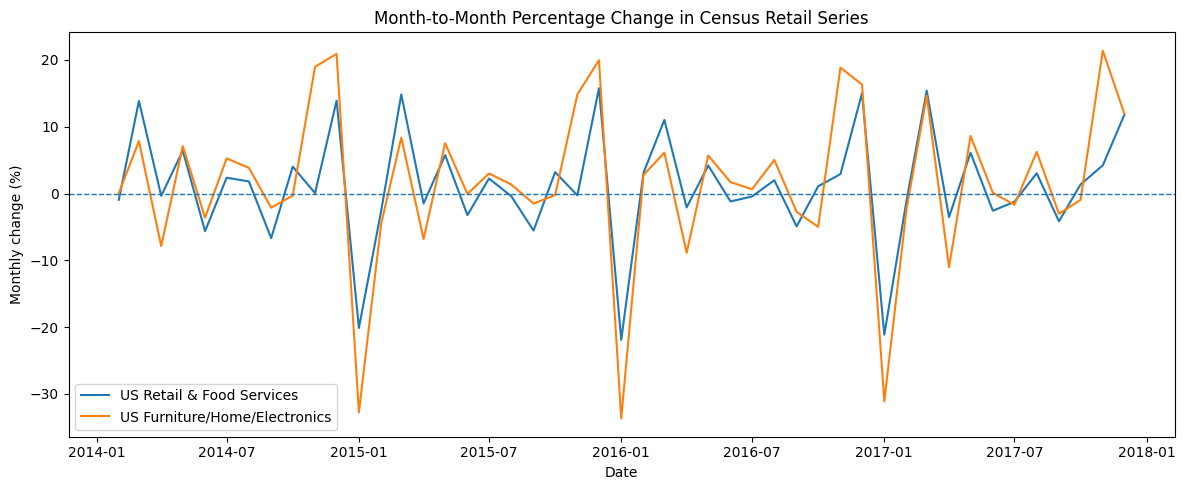

In [74]:
# Visualising the short-run variation within the Census dataset
plt.figure(figsize=(12, 5))

plt.plot(
    census_exploration["Date"],
    census_exploration["Census Total Sales MoM %"],
    label="US Retail & Food Services"
)

plt.plot(
    census_exploration["Date"],
    census_exploration["Census Furniture/Electronics Sales MoM %"],
    label="US Furniture/Home/Electronics"
)

plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)

plt.title(
    "Month-to-Month Percentage Change in Census Retail Series"
)
plt.xlabel("Date")
plt.ylabel("Monthly change (%)")
plt.legend()

plt.tight_layout()
plt.show()

In [75]:
# Ensuring the date column is datetime
df["Order Date"] = pd.to_datetime(
    df["Order Date"]
)

# Restricting it to the Census comparison period
superstore_period = df[
    (df["Order Date"] >= "2014-01-01") &
    (df["Order Date"] <= "2017-12-31")
].copy()

# Aggregating transaction-line Sales into monthly totals
superstore_monthly = (
    superstore_period
    .set_index("Order Date")
    .resample("MS")["Sales"]
    .sum()
    .reset_index()
)

superstore_monthly = superstore_monthly.rename(
    columns={
        "Order Date": "Date",
        "Sales": "Superstore Sales"
    }
)

display(superstore_monthly.head(12))

,Date,Superstore Sales
0,2014-01-01,14236.8950
1,2014-02-01,4519.8920
2,2014-03-01,55691.0090
3,2014-04-01,28295.3450
4,2014-05-01,23648.2870
5,2014-06-01,34595.1276
6,2014-07-01,33946.3930
7,2014-08-01,27909.4685
8,2014-09-01,81777.3508
9,2014-10-01,31453.3930


In [76]:
comparison = (
    superstore_monthly
    .merge(
        census_total,
        on="Date",
        how="inner"
    )
    .merge(
        census_furniture,
        on="Date",
        how="inner"
    )
)

display(comparison.head())
print(comparison.shape)

,Date,Superstore Sales,Census Total Sales,Census Furniture/Electronics Sales
0,2014-01-01,14236.895,376896,14847
1,2014-02-01,4519.892,373381,14857
2,2014-03-01,55691.009,425114,16023
3,2014-04-01,28295.345,423637,14762
4,2014-05-01,23648.287,450823,15810


(48, 4)


In [77]:
series_columns = [
    "Superstore Sales",
    "Census Total Sales",
    "Census Furniture/Electronics Sales"
]

for column in series_columns:

    base_value = comparison.loc[
        comparison["Date"] == "2014-01-01",
        column
    ].iloc[0]

    comparison[f"{column} Index"] = (
        comparison[column] /
        base_value *
        100
    )

display(
    comparison[
        [
            "Date",
            "Superstore Sales Index",
            "Census Total Sales Index",
            "Census Furniture/Electronics Sales Index"
        ]
    ].head()
)

,Date,Superstore Sales Index,Census Total Sales Index,Census Furniture/Electronics Sales Index
0,2014-01-01,100.000000,100.000000,100.000000
1,2014-02-01,31.747737,99.067382,100.067354
2,2014-03-01,391.173841,112.793450,107.920792
3,2014-04-01,198.746602,112.401564,99.427494
4,2014-05-01,166.105650,119.614695,106.486159


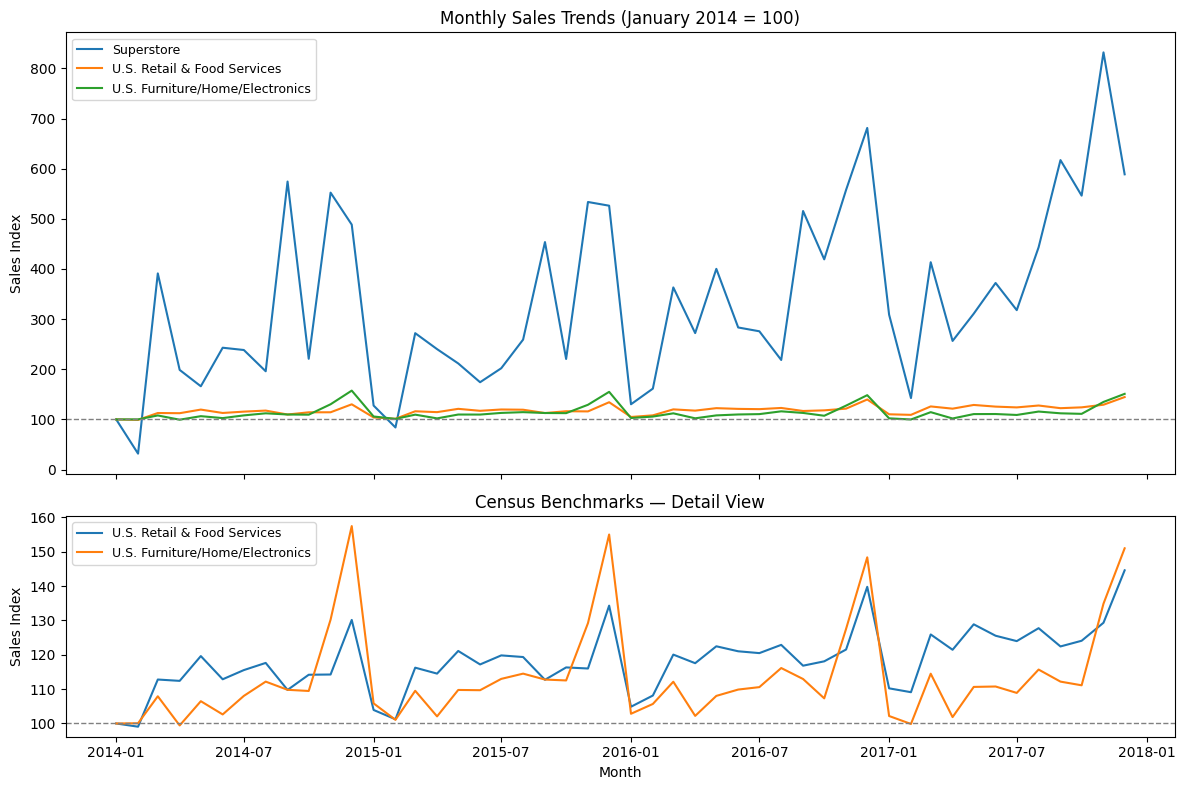

In [78]:
# Both panels use the same January 2014 = 100 indexed sales series.
# The second panel zooms in on the Census benchmarks for readability.
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True,
                         gridspec_kw={"height_ratios": [2, 1]})
axes[0].plot(comparison["Date"], comparison["Superstore Sales Index"],
             label="Superstore")
axes[0].plot(comparison["Date"], comparison["Census Total Sales Index"],
             label="U.S. Retail & Food Services")
axes[0].plot(comparison["Date"], comparison["Census Furniture/Electronics Sales Index"],
             label="U.S. Furniture/Home/Electronics")
axes[0].axhline(100, linestyle="--", linewidth=1, color="gray")
axes[0].set_title("Monthly Sales Trends (January 2014 = 100)")
axes[0].set_ylabel("Sales Index")
axes[0].legend(loc="upper left", fontsize=9)
axes[1].plot(comparison["Date"], comparison["Census Total Sales Index"],
             label="U.S. Retail & Food Services")
axes[1].plot(comparison["Date"], comparison["Census Furniture/Electronics Sales Index"],
             label="U.S. Furniture/Home/Electronics")
axes[1].axhline(100, linestyle="--", linewidth=1, color="gray")
axes[1].set_title("Census Benchmarks — Detail View")
axes[1].set_ylabel("Sales Index")
axes[1].set_xlabel("Month")
axes[1].legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

In [79]:
# Quantify the relationship between the indexed monthly sales series
correlation = comparison[
    [
        "Superstore Sales Index",
        "Census Total Sales Index",
        "Census Furniture/Electronics Sales Index"
    ]
].corr()

display(correlation.round(3))


,Superstore Sales Index,Census Total Sales Index,Census Furniture/Electronics Sales Index
Superstore Sales Index,1.000,0.645,0.690
Census Total Sales Index,0.645,1.000,0.725
Census Furniture/Electronics Sales Index,0.690,0.725,1.000


### Interpretation of the Census comparison

The indexed comparison shows that **Superstore monthly sales are substantially more volatile than the two national Census benchmarks**. Superstore experiences large month-to-month swings, while total U.S. retail sales and the furniture/home furnishings/electronics series remain within a much narrower range. The correlation table provides a quantitative check on whether the series move together, while the chart shows that any broad similarity in direction is accompanied by much greater retailer-specific volatility.

This suggests that Superstore's monthly performance is influenced strongly by **company- and customer-specific factors**, such as the timing of large orders, customer mix, product mix and promotional activity, rather than simply mirroring national retail conditions. The Census MRTS data should therefore be treated as **external market context rather than validation of the RFM/K-means customer segments**. The two sources operate at different levels of granularity: Superstore contains individual transactions for one retailer, whereas MRTS reports aggregate U.S. retail activity.

The comparison also highlights an important limitation when generalising the Superstore findings. Even though the Census furniture/home furnishings/electronics series provides a closer product-market benchmark than total retail sales, it is still not an exact match for Superstore's category mix. In addition, the analysis deliberately uses **NOT ADJUSTED** Census data so that seasonal movements remain comparable with the raw Superstore sales series. As a result, observed monthly variation can reflect both underlying market conditions and normal seasonal effects.


## 10. Business takeaways and limitations

- **Prioritise High-Value Loyal customers** for relationship maintenance. **Target Established Profitable customers** for re-engagement tests, given their longer average recency.
- **Avoid expensive blanket offers to Low-Value Dormant customers** without evidence of incremental benefit.
- **Review discount eligibility and unprofitable product combinations** in the High-Revenue Loss-Making group before directing more promotional spending toward it. Machines, Binders and Tables account for the largest negative sub-category results within this group.
- **Interpret findings cautiously:** these are historical descriptive segments, not causal effects, campaign ROI, predictive CLV or universal customer types. Census correlations are external context; no retailer-level causal explanation is established.

**Possible next step:** Link customer histories to campaign costs, treatment/control status and product-level contribution margin, then evaluate retention tests and out-of-time segment stability.